# 03 · Exploratory data analysis

**Why.** Understand the population before fitting anything: how rare the outcome is, which answers differ between groups, and which answers move together (possible confounding).

In [1]:
# Every notebook reads the committed aggregate reports, so it runs from a fresh clone without the survey data.
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ENDPOINT = "combined"  # "prediabetes" shows the sensitivity analysis instead
REPORTS = ROOT / "reports"
STAGE_1_4 = REPORTS / ("uploaded-combined" if ENDPOINT == "combined" else "prediabetes")
MODELING = REPORTS / "modeling" / ENDPOINT
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def figure(path, width=860):
    display(Image(filename=str(path), width=width))

## How common is the outcome?

In [2]:
balance = pd.read_csv(STAGE_1_4 / "eda" / "class_balance.csv")
balance

,Diabetes_binary,count,fraction
0,0,213703,0.842
1,1,39977,0.158


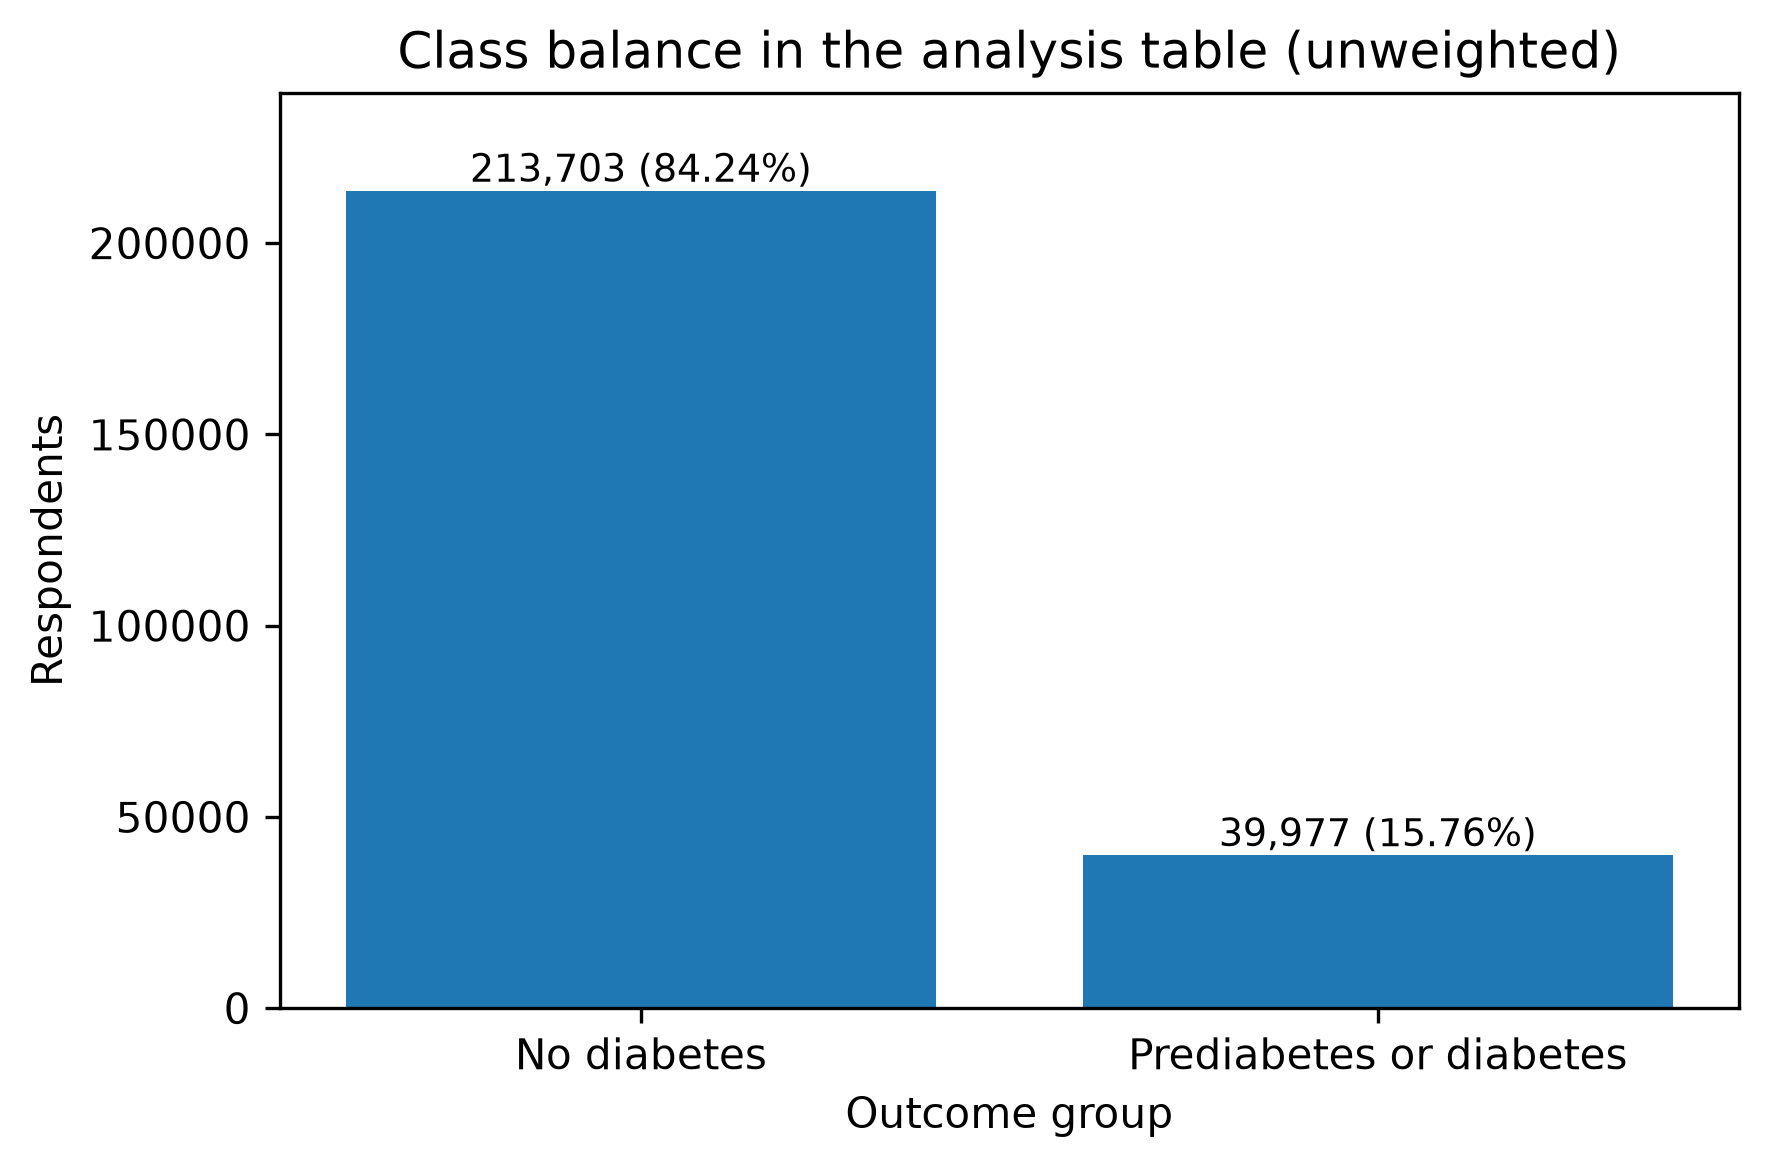

In [3]:
figure(STAGE_1_4 / "eda" / "class_balance.png", width=560)

About one adult in six reports prediabetes or diabetes. Accuracy would be misleading here (always answering "no" scores 84%), which is why the later stages use PR-AUC, recall and precision.

## BMI and age by outcome

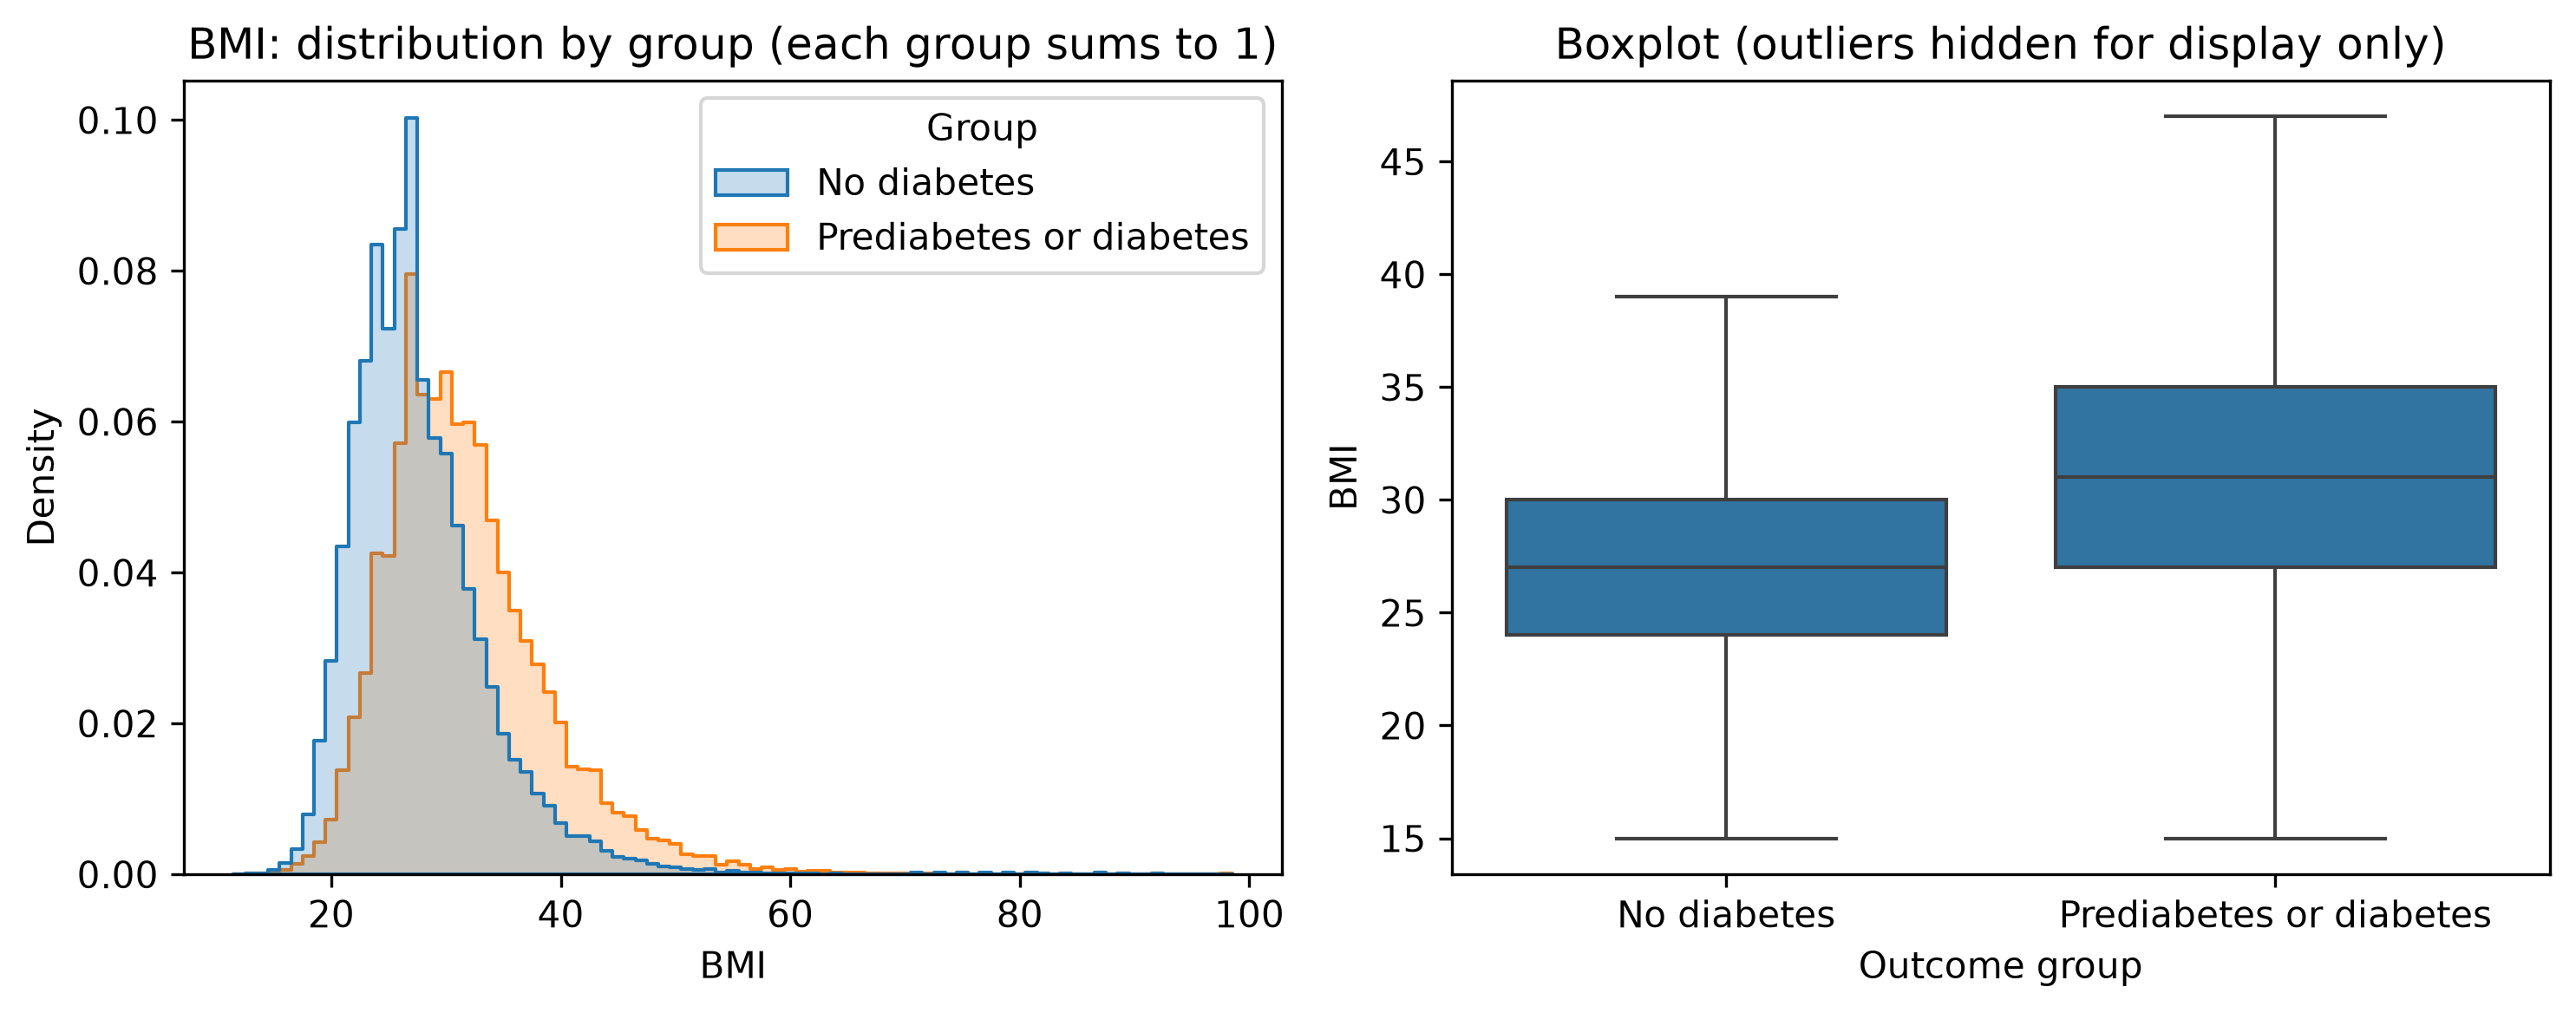

In [4]:
figure(STAGE_1_4 / "eda" / "distribution_BMI.png")

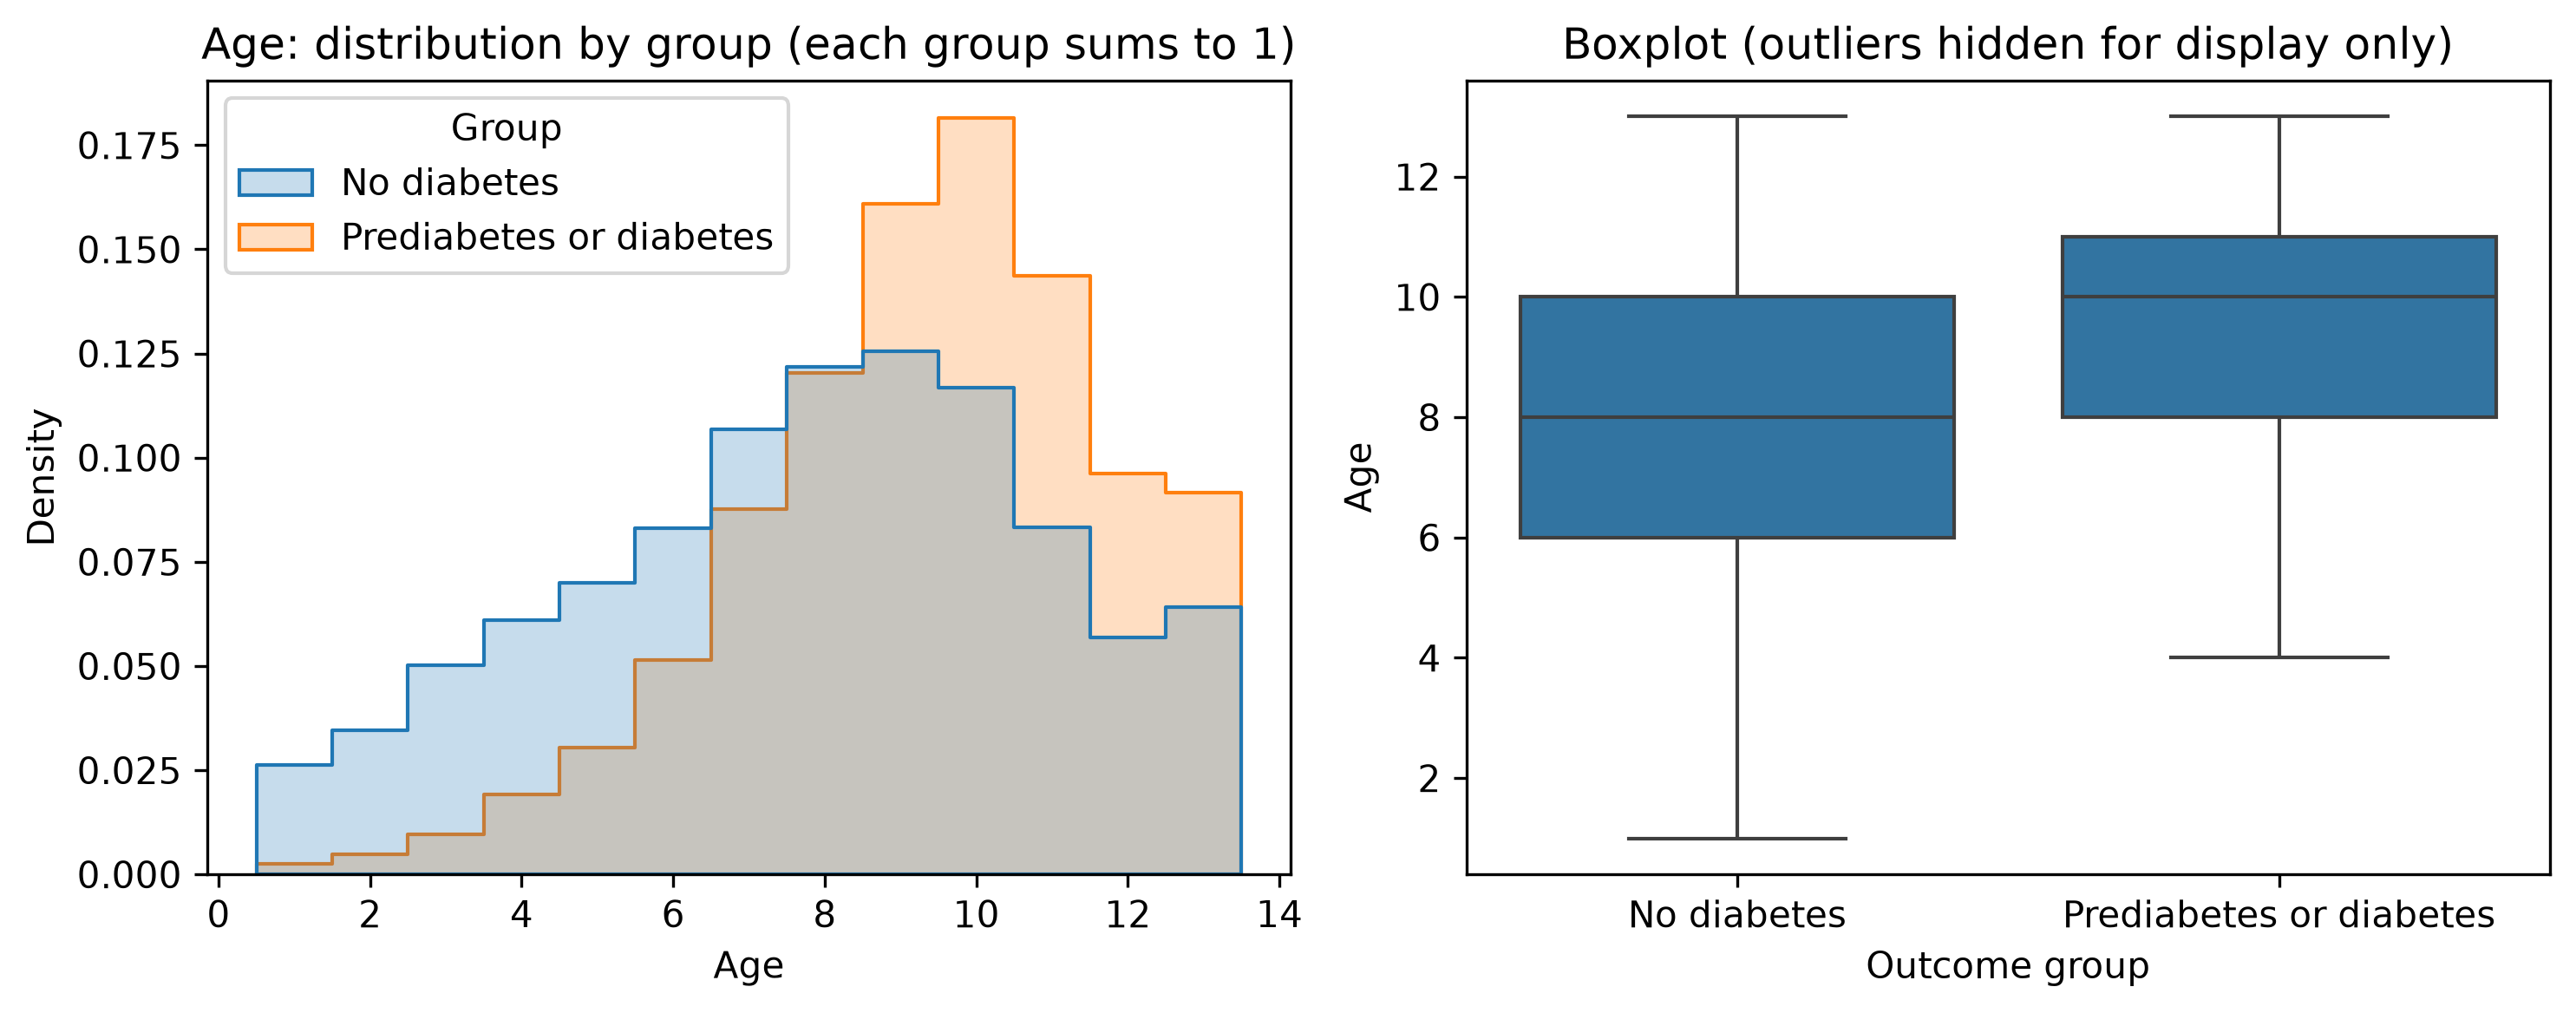

In [5]:
figure(STAGE_1_4 / "eda" / "distribution_Age.png")

## Share with the outcome across each yes/no answer

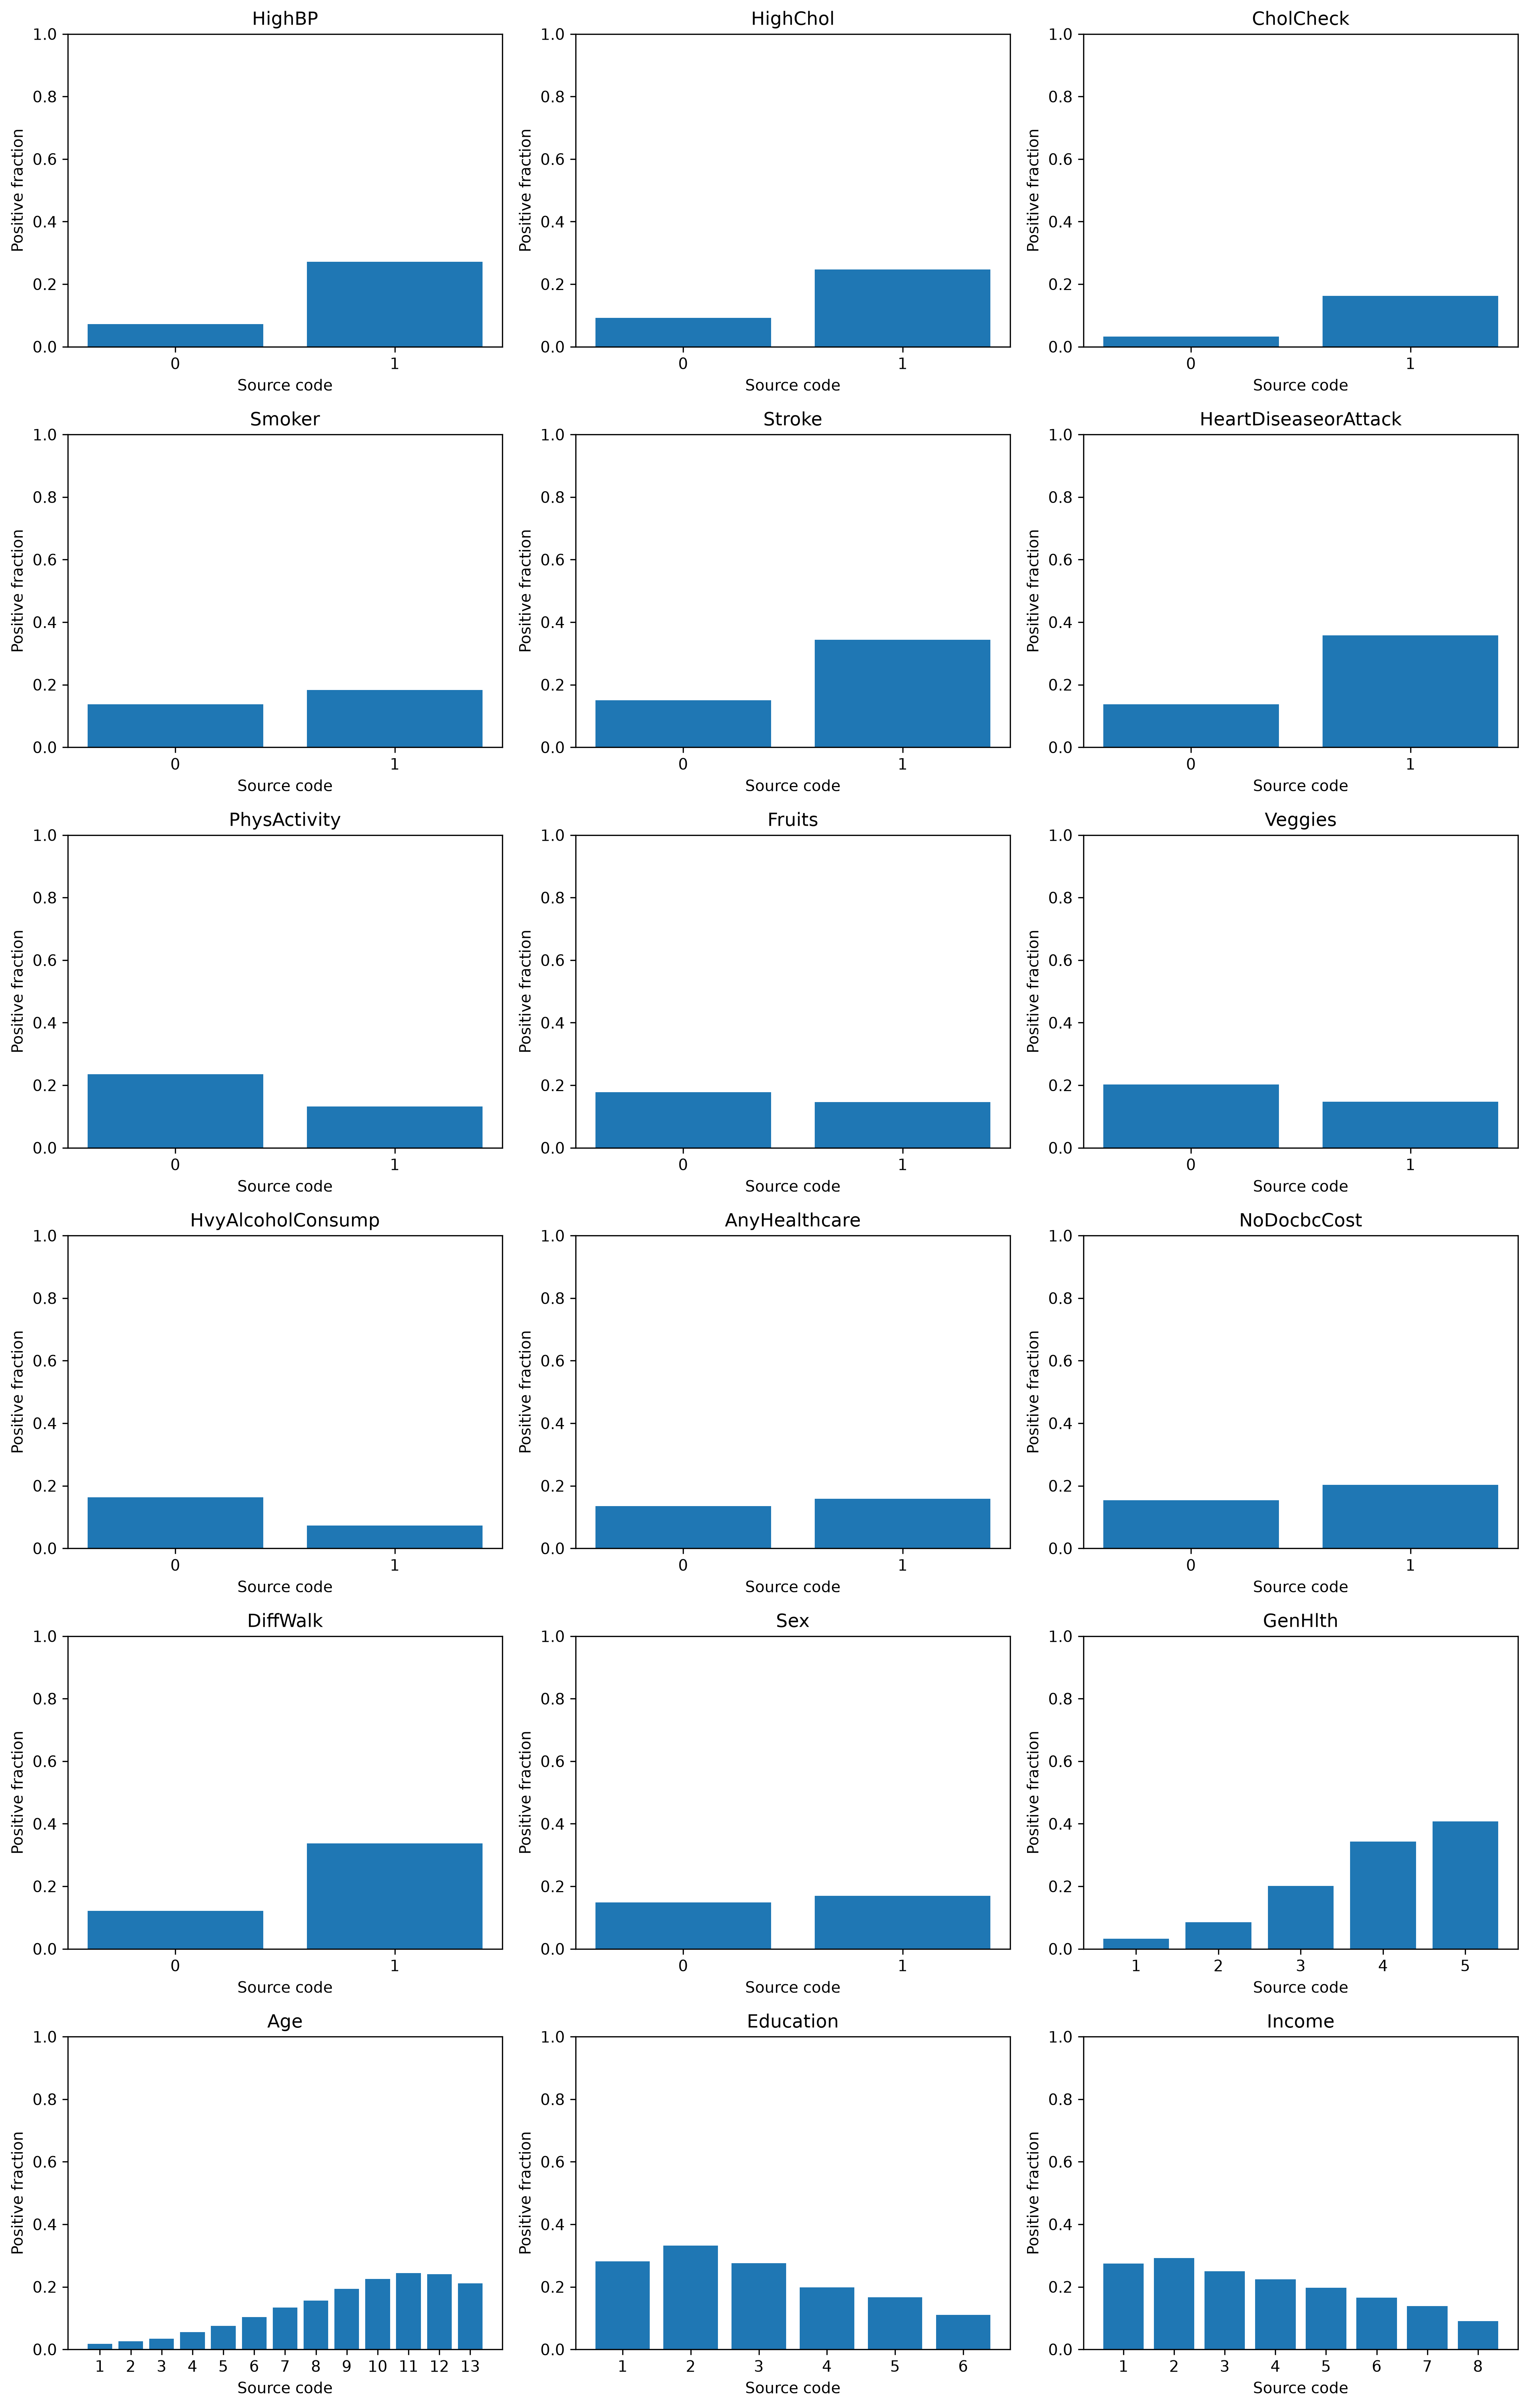

In [6]:
figure(STAGE_1_4 / "eda" / "categorical_factors.png")

## Which answers move together (Spearman)

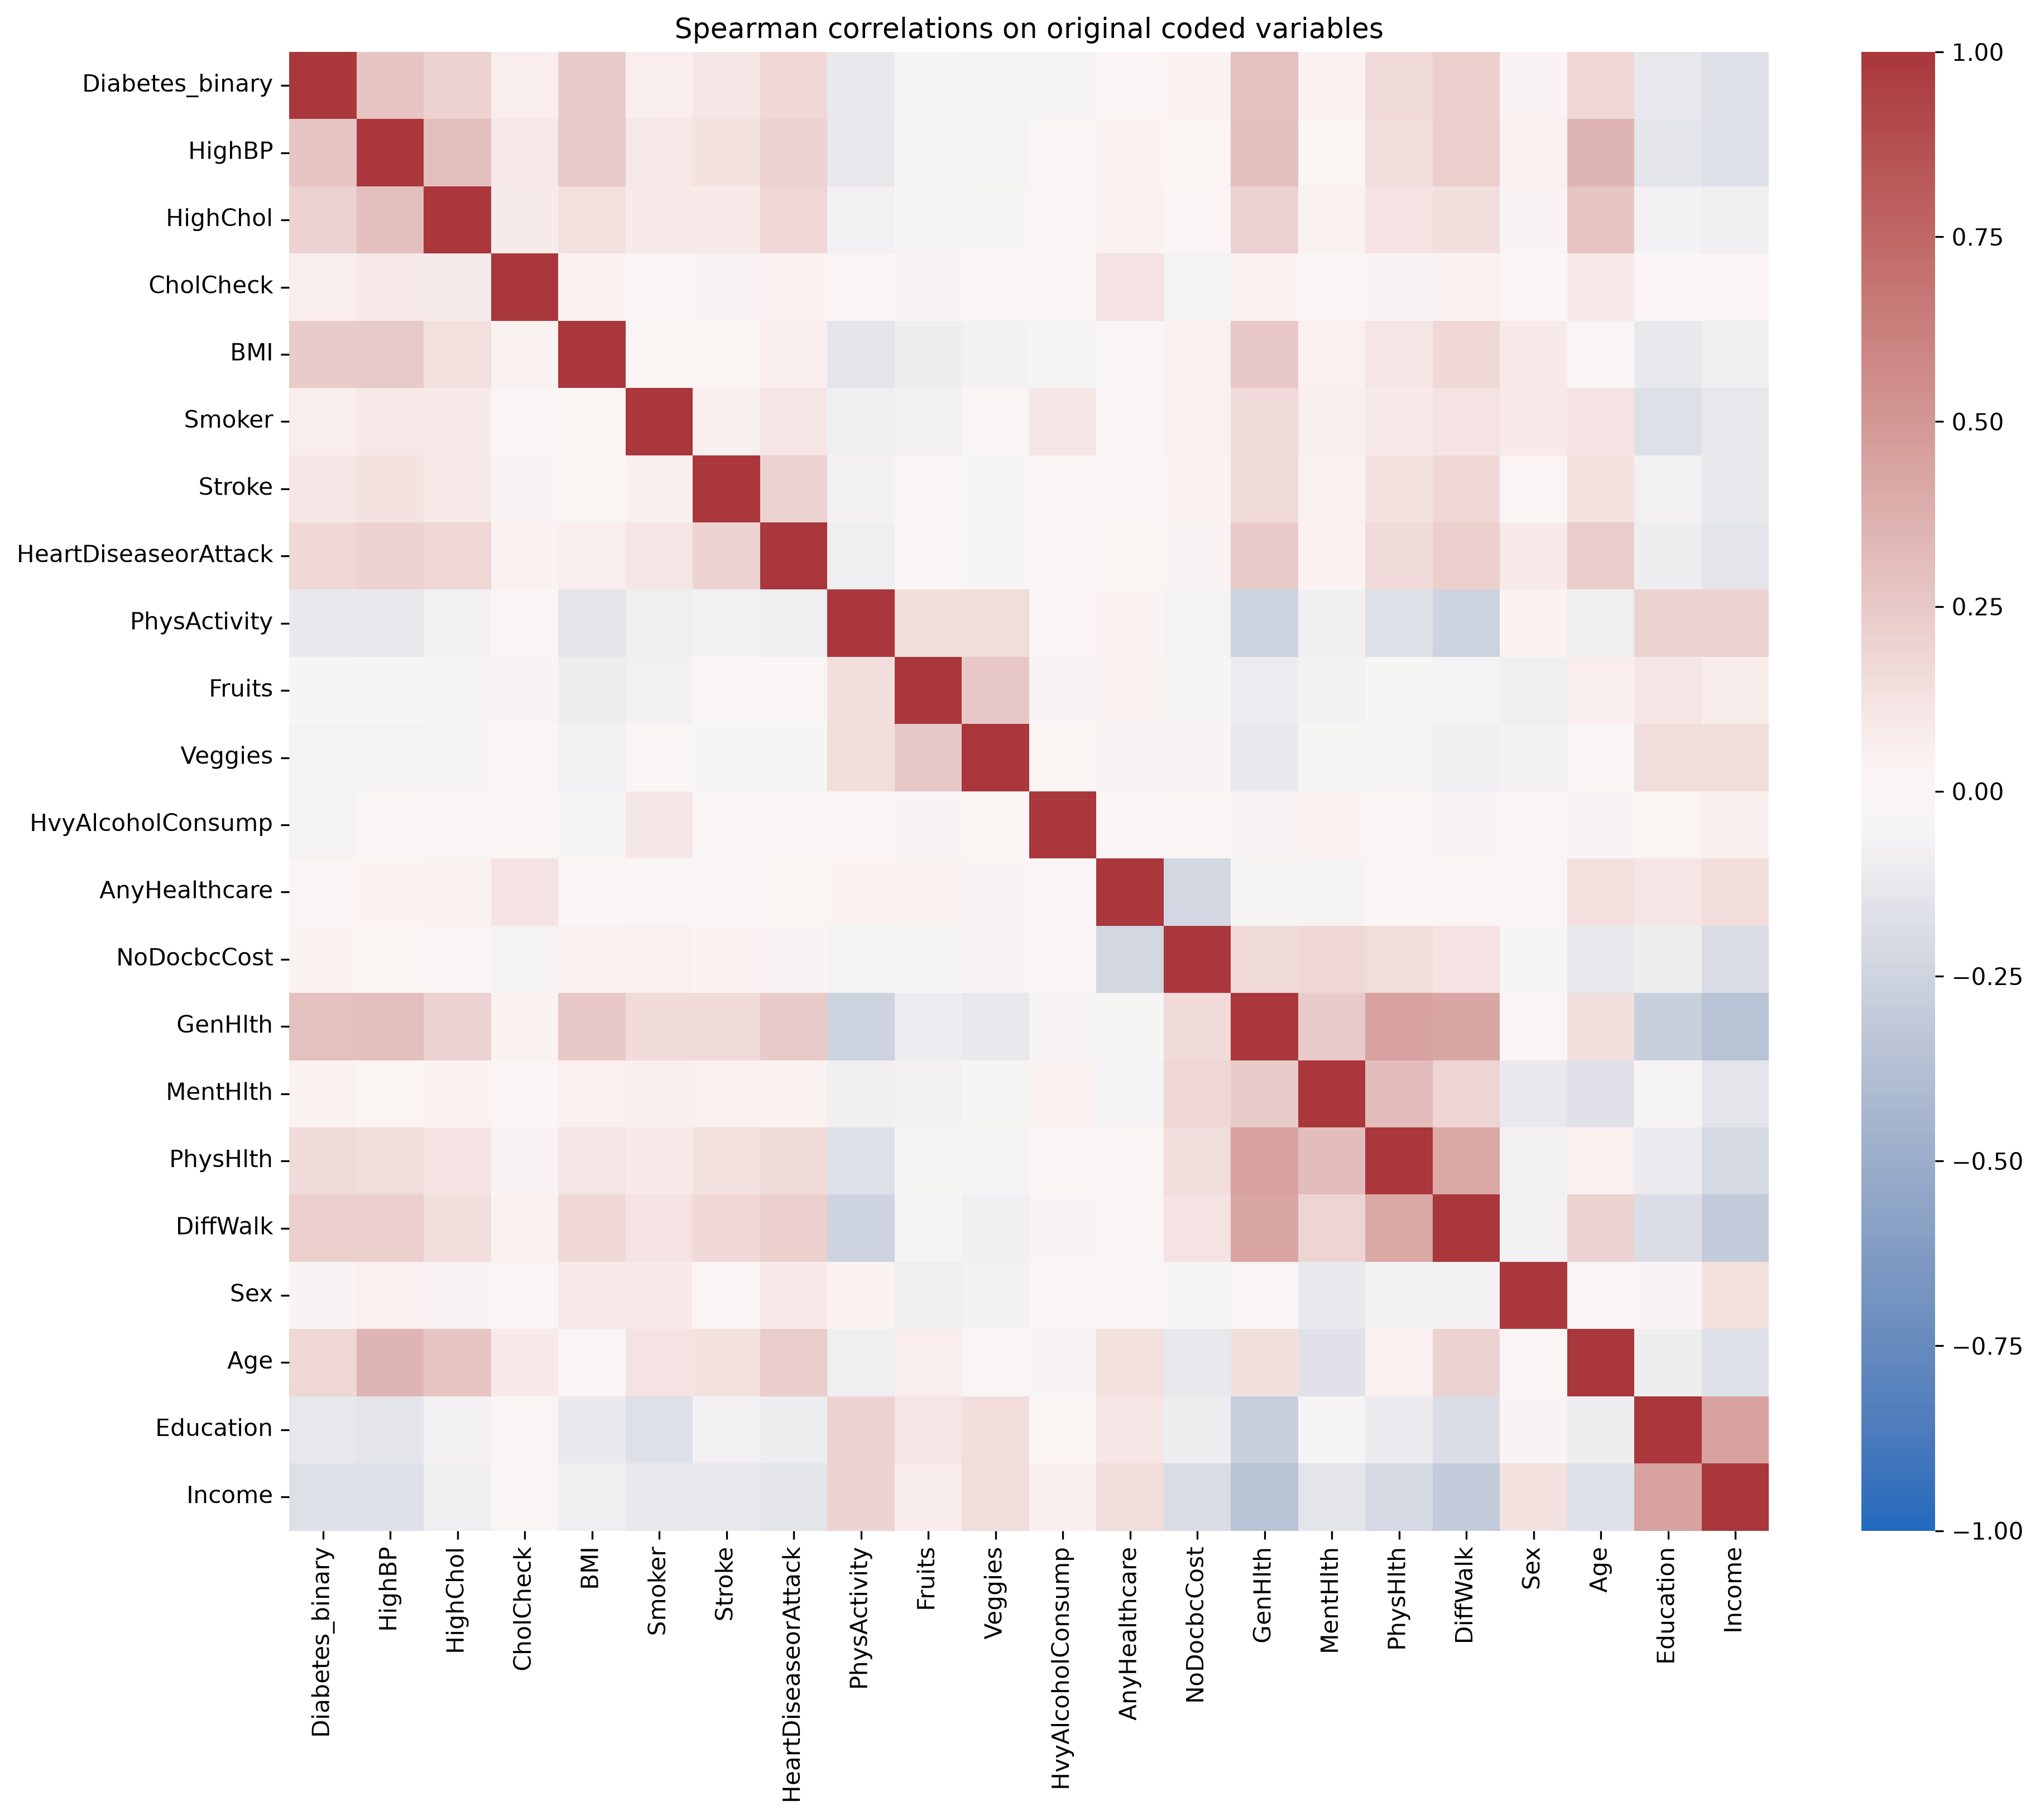

In [7]:
figure(STAGE_1_4 / "eda" / "correlations_spearman.png", width=760)

## Written observations (generated from the data)

In [8]:
display(Markdown((STAGE_1_4 / "eda" / "observations.md").read_text(encoding="utf-8")))

# Exploratory observations

Analysis cohort: 253,680 rows; positive fraction: 15.76%.
Binary endpoint: combined.
This is the observed table fraction, not a survey-weighted population estimate.

- BMI: median 27 in group 0; 31 in group 1.
- Age: median 8 in group 0; 10 in group 1.
- MentHlth: median 0 in group 0; 0 in group 1.
- PhysHlth: median 0 in group 0; 1 in group 1.
- GenHlth: median 2 in group 0; 3 in group 1.

Strongest Spearman correlations with the outcome (descriptive; coded variables): GenHlth +0.296; HighBP +0.270; BMI +0.235; DiffWalk +0.222; HighChol +0.210.

Largest unadjusted prevalence ratios among binary factors (code 1 vs code 0; not odds ratios): CholCheck 5.08x (16.25% vs 3.20%); HighBP 3.76x (27.12% vs 7.22%); DiffWalk 2.79x (33.76% vs 12.12%); HighChol 2.69x (24.69% vs 9.18%); HeartDiseaseorAttack 2.61x (35.75% vs 13.68%).

Age and general health are ordinal codes. Correlations depend on coding; use Spearman as an ordered-rank complement to Pearson. Group differences can reflect age, healthcare access, and other confounding. No causal or diagnostic conclusions follow. Later modeling must keep hold-out data isolated; this full-cohort exploration is descriptive and must not be used to tune test-set decisions.


**Takeaway.** General health, high blood pressure, BMI, difficulty walking and high cholesterol have the strongest correlations with the outcome, and the positive group is older (median age band 65–69 against 55–59). Several of these answers are correlated with each other, so single-answer comparisons can overstate effects; stage 6's adjusted odds ratios check that.

This is a research prototype for risk stratification, not a diagnostic or clinical decision tool. The outcome is self-reported, the data are cross-sectional and unweighted, and associations are not causes.